In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow
import seaborn as sns

In [8]:
metmast_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/metmast-cleaned/metmast-data-cleaned"
anem_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-cleaned/anem-data-cleaned"
lidar159_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG159_lidar.parquet"
lidar170_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG170_lidar.parquet"
lidar171_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG171_lidar.parquet"
lidar173_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG173_lidar.parquet"
lidar180_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG180_lidar.parquet"
lidar184_path = "/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/lidar-cleaned/WTG184_lidar.parquet"

metmast = pd.read_parquet(metmast_path)
scada = pd.read_parquet(anem_path)
lidar159 = pd.read_parquet(lidar159_path)
lidar170 = pd.read_parquet(lidar170_path)
lidar171 = pd.read_parquet(lidar171_path)
lidar173 = pd.read_parquet(lidar173_path)
lidar180 = pd.read_parquet(lidar180_path)
lidar184 = pd.read_parquet(lidar184_path)

In [9]:
metmast.head()

,utc,mm_wind_speed_1,mm_wind_speed_2,mm_wind_speed_3,mm_wind_speed_hh,mm_wind_direction_1,mm_wind_direction_2,mm_wind_direction_3,mm_wind_direction_hh,mm_pressure_bar_1,mm_pressure_bar_2,mm_rel_humidity_1,mm_rel_humidity_2,mm_temp_amb
0,2026-01-01 08:00:00,NaN,6.788382,5.399412,0.700615,71.916912,54.936030,67.719853,47.655736,NaN,875.645740,11.372340,4.810286,NaN
1,2026-01-01 08:10:00,NaN,6.259118,5.094412,0.697460,67.399852,51.146323,64.681471,43.452206,NaN,875.537235,11.323674,4.573111,NaN
2,2026-01-01 08:20:00,NaN,6.533529,5.542794,0.703226,72.914559,57.126323,70.034118,51.133089,NaN,875.370256,11.276522,4.534419,NaN
3,2026-01-01 08:30:00,NaN,6.125970,5.133824,0.711940,86.105735,65.834329,84.872500,58.976618,NaN,875.402339,11.249778,4.145185,NaN
4,2026-01-01 08:40:00,NaN,5.931143,5.168986,0.691642,90.357286,68.262572,87.822753,61.110143,NaN,875.489709,11.124737,4.001458,NaN


In [10]:
lidar180.head()

,utc,turbine,wind_speed_l,wind_speed_l_std,wind_direction_l,n_available_l,control,wind_speed_l1,wind_speed_l1_std,wind_speed_l2,wind_speed_l2_std,wind_direction_l1,wind_direction_l2
0,2026-04-01 08:00:00,WTG180,10.95,1.23,1.13,595.0,0,12.36,1.44,0.0,0.0,-4.30,0.0
1,2026-04-01 08:10:00,WTG180,9.90,1.46,1.74,594.0,0,11.48,1.75,0.0,0.0,-2.61,0.0
2,2026-04-01 08:20:00,WTG180,9.13,0.86,0.91,594.0,0,10.33,1.30,0.0,0.0,-3.99,0.0
3,2026-04-01 08:30:00,WTG180,9.66,0.67,0.03,593.0,0,10.81,1.19,0.0,0.0,-4.06,0.0
4,2026-04-01 08:40:00,WTG180,9.83,0.90,-1.00,595.0,0,11.56,1.25,0.0,0.0,-6.88,0.0


In [11]:
scada.head()

,utc,turbine,air_density,KPI_temp_ambient_merged,KPI_temp_ambient,KPI_theoretical_power,KPI_real_power_ac,real_power_ac,KPI_wind_speed,wind_speed,wind_direction,wind_direction_relative,nacelle_pos,blade_1_pos,blade_2_pos,blade_3_pos,blade_1_setpos,blade_2_setpos,blade_3_setpos
0,2026-01-01 08:00:00,WTG150,1.092081,8.299405,8.299405,746.68463,672.60510,670.286714,6.906036,6.907681,115.629870,-1.392857,118.785714,NaN,-1.056245,-0.643520,2.307242,-0.892182,-0.471435
1,2026-01-01 08:00:00,WTG151,1.087094,9.592089,9.592089,406.01855,485.57794,485.492347,5.730449,5.717620,116.709677,6.439716,113.500000,0.614472,-0.925170,1.124203,0.856155,-0.676644,1.384543
2,2026-01-01 08:00:00,WTG152,1.090355,8.745550,8.745550,440.09213,497.79605,496.384967,5.862610,5.836812,252.291139,-5.909091,259.600000,-0.481281,0.200810,0.278822,NaN,NaN,NaN
3,2026-01-01 08:00:00,WTG153,1.044950,21.009600,21.009600,445.82935,423.57132,422.188638,5.969328,5.951737,283.955414,-6.215278,291.230769,-0.059970,0.342474,-0.278986,-0.027131,0.376825,-0.244748
4,2026-01-01 08:00:00,WTG154,1.088453,9.238713,9.238713,208.84138,274.52768,274.276035,4.760764,4.757731,139.118343,-4.608108,140.000000,-1.428621,1.907079,1.215503,-1.376194,1.938141,1.257423


In [20]:
scada["utc"] = scada["utc"] + pd.to_timedelta(8, unit="h")

In [21]:
wtg180 = scada[scada['turbine'] == 'WTG180']

In [22]:
wtg180.shape

(39018, 19)

In [23]:
wtg180_combined = pd.merge(lidar180, wtg180, on="utc", how="inner")
wtg180_combined = wtg180_combined.rename(columns={"KPI_wind_speed": "ws_anem", "wind_speed_l": "ws_lidar", "KPI_real_power_ac": "power"})

In [24]:
print(wtg180_combined.columns.tolist())

['utc', 'turbine_x', 'ws_lidar', 'wind_speed_l_std', 'wind_direction_l', 'n_available_l', 'control', 'wind_speed_l1', 'wind_speed_l1_std', 'wind_speed_l2', 'wind_speed_l2_std', 'wind_direction_l1', 'wind_direction_l2', 'turbine_y', 'air_density', 'KPI_temp_ambient_merged', 'KPI_temp_ambient', 'KPI_theoretical_power', 'power', 'real_power_ac', 'ws_anem', 'wind_speed', 'wind_direction', 'wind_direction_relative', 'nacelle_pos', 'blade_1_pos', 'blade_2_pos', 'blade_3_pos', 'blade_1_setpos', 'blade_2_setpos', 'blade_3_setpos']


In [30]:
wtg180_combined = wtg180_combined[
    (wtg180_combined["ws_lidar"].between(3, 25)) &          # normal operating range
    (wtg180_combined["power"] > 0)                         # turbine actually running
].dropna(subset=["ws_anem", "ws_lidar"])

Bias: -0.18704934765008574  RMSE: 0.7476269291522771
anem = 0.974 * lidar + 0.092


/var/folders/gq/h1h8jf9s2ljgh3cq6yfxgcbm0000gn/T/ipykernel_34622/2641116727.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wtg180_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")


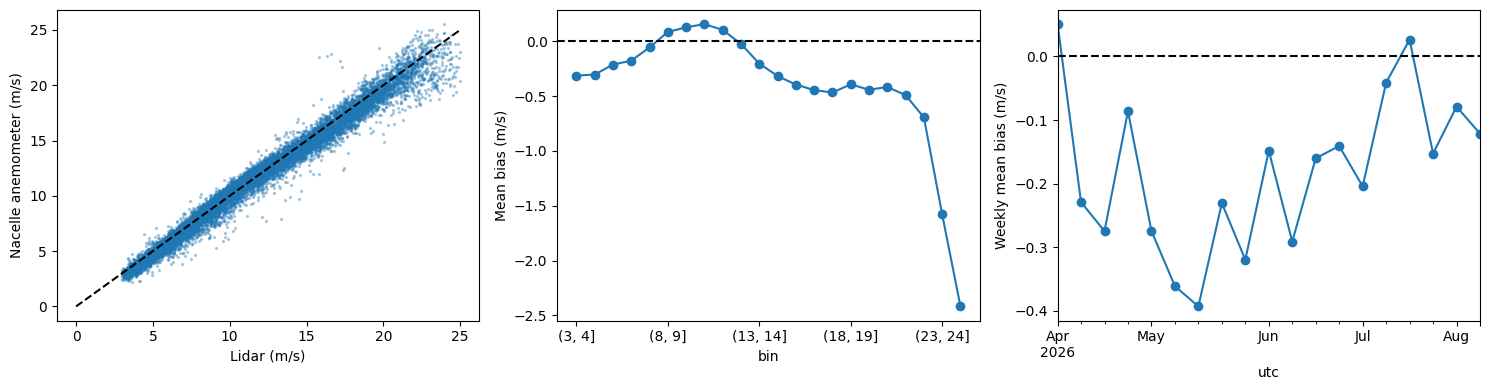

In [31]:
diff = wtg180_combined["ws_anem"] - wtg180_combined["ws_lidar"]
print("Bias:", diff.mean(), " RMSE:", np.sqrt((diff**2).mean()))
slope, intercept = np.polyfit(wtg180_combined["ws_lidar"], wtg180_combined["ws_anem"], 1)
print(f"anem = {slope:.3f} * lidar + {intercept:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Scatter vs 1:1 line
ax[0].scatter(wtg180_combined["ws_lidar"], wtg180_combined["ws_anem"], s=2, alpha=0.3)
ax[0].plot([0, 25], [0, 25], "k--")
ax[0].set(xlabel="Lidar (m/s)", ylabel="Nacelle anemometer (m/s)")

# Bias by wind speed bin
bins = np.arange(3, 26, 1)
wtg180_combined["bin"] = pd.cut(wtg180_combined["ws_lidar"], bins)
wtg180_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(ylabel="Mean bias (m/s)")

# Bias over time: this is where faults show up
diff.groupby(wtg180_combined["utc"].dt.to_period("W")).mean().plot(ax=ax[2], marker="o")
ax[2].axhline(0, color="k", ls="--"); ax[2].set(ylabel="Weekly mean bias (m/s)")
plt.tight_layout()

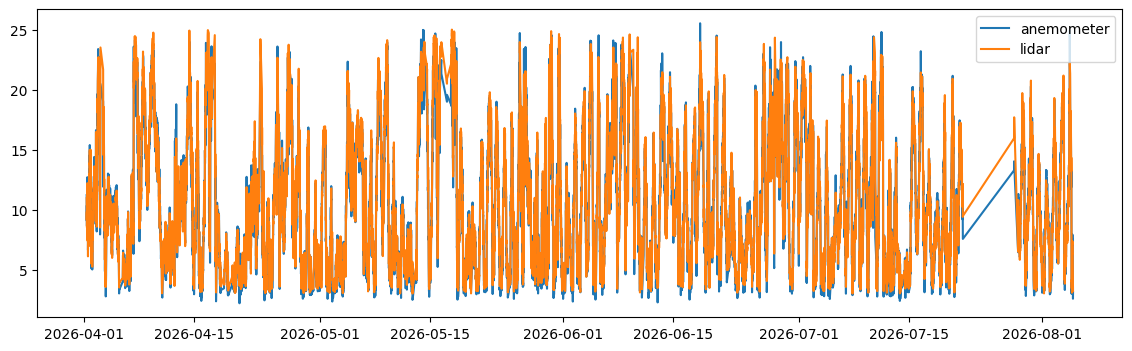

In [32]:
#check bc windspeed graph looks kinda cray
wk = wtg180_combined[(wtg180_combined["utc"] >= "2026-04-01") & (wtg180_combined["utc"] < "2026-09-30")]   # pick a week in your data
plt.figure(figsize=(14, 4))
plt.plot(wk["utc"], wk["ws_anem"], label="anemometer")
plt.plot(wk["utc"], wk["ws_lidar"], label="lidar")
plt.legend()

## turbine 159

Bias: 1.0875156158888197  RMSE: 1.4013213940181102
anem = 1.193 * lidar + -0.808


/var/folders/gq/h1h8jf9s2ljgh3cq6yfxgcbm0000gn/T/ipykernel_34622/2200359447.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wtg159_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")


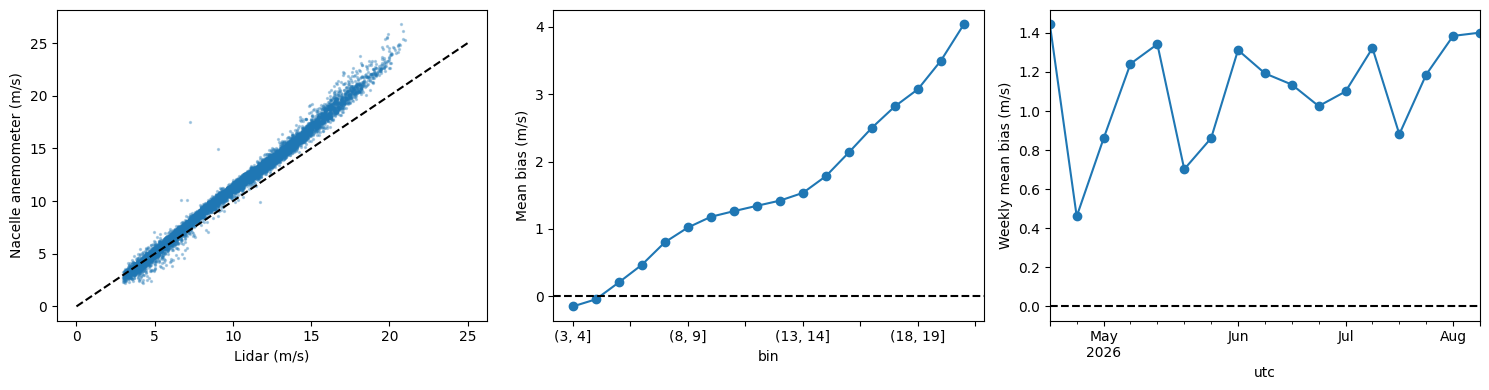

In [34]:
#subset turbine 159
wtg159 = scada[scada['turbine'] == 'WTG159']

#combine lidar and scada
wtg159_combined = pd.merge(lidar159, wtg159, on="utc", how="inner")
wtg159_combined = wtg159_combined.rename(columns={"KPI_wind_speed": "ws_anem", "wind_speed_l": "ws_lidar", "KPI_real_power_ac": "power"})

#filter out nas, when the turbine is off, and outliers (turbines performing outside of normal operating range)
wtg159_combined = wtg159_combined[
    (wtg159_combined["ws_lidar"].between(3, 25)) &          # normal operating range
    (wtg159_combined["power"] > 0)                         # turbine actually running
].dropna(subset=["ws_anem", "ws_lidar"])

#compute bias, rmse and plot
diff = wtg159_combined["ws_anem"] - wtg159_combined["ws_lidar"]
print("Bias:", diff.mean(), " RMSE:", np.sqrt((diff**2).mean()))
slope, intercept = np.polyfit(wtg159_combined["ws_lidar"], wtg159_combined["ws_anem"], 1)
print(f"anem = {slope:.3f} * lidar + {intercept:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Scatter vs 1:1 line
ax[0].scatter(wtg159_combined["ws_lidar"], wtg159_combined["ws_anem"], s=2, alpha=0.3)
ax[0].plot([0, 25], [0, 25], "k--")
ax[0].set(xlabel="Lidar (m/s)", ylabel="Nacelle anemometer (m/s)")

# Bias by wind speed bin
bins = np.arange(3, 26, 1)
wtg159_combined["bin"] = pd.cut(wtg159_combined["ws_lidar"], bins)
wtg159_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(ylabel="Mean bias (m/s)")

# Bias over time: this is where faults show up
diff.groupby(wtg159_combined["utc"].dt.to_period("W")).mean().plot(ax=ax[2], marker="o")
ax[2].axhline(0, color="k", ls="--"); ax[2].set(ylabel="Weekly mean bias (m/s)")
plt.tight_layout()

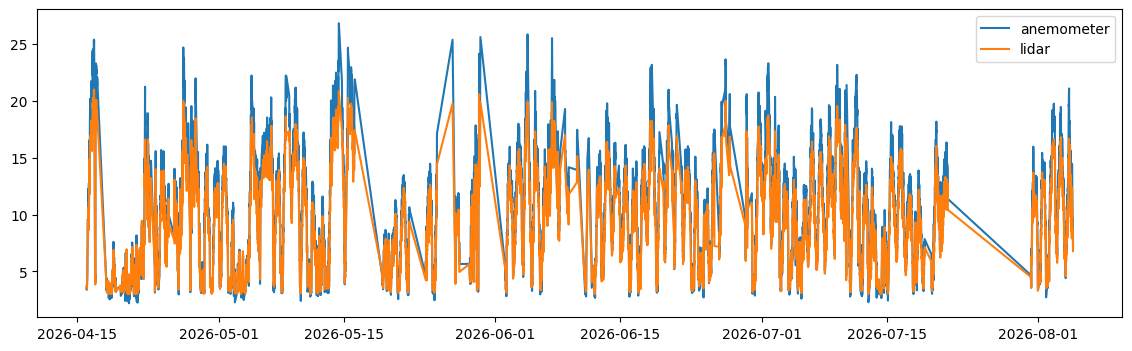

In [35]:
#check bc windspeed graph looks kinda cray
wk = wtg159_combined[(wtg159_combined["utc"] >= "2026-04-01") & (wtg159_combined["utc"] < "2026-09-30")]   # pick a week in your data
plt.figure(figsize=(14, 4))
plt.plot(wk["utc"], wk["ws_anem"], label="anemometer")
plt.plot(wk["utc"], wk["ws_lidar"], label="lidar")
plt.legend()

## turbine 184

Bias: 0.4467360624450897  RMSE: 0.7605540343786948
anem = 1.125 * lidar + -0.676


/var/folders/gq/h1h8jf9s2ljgh3cq6yfxgcbm0000gn/T/ipykernel_34622/2608353899.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wtg184_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")


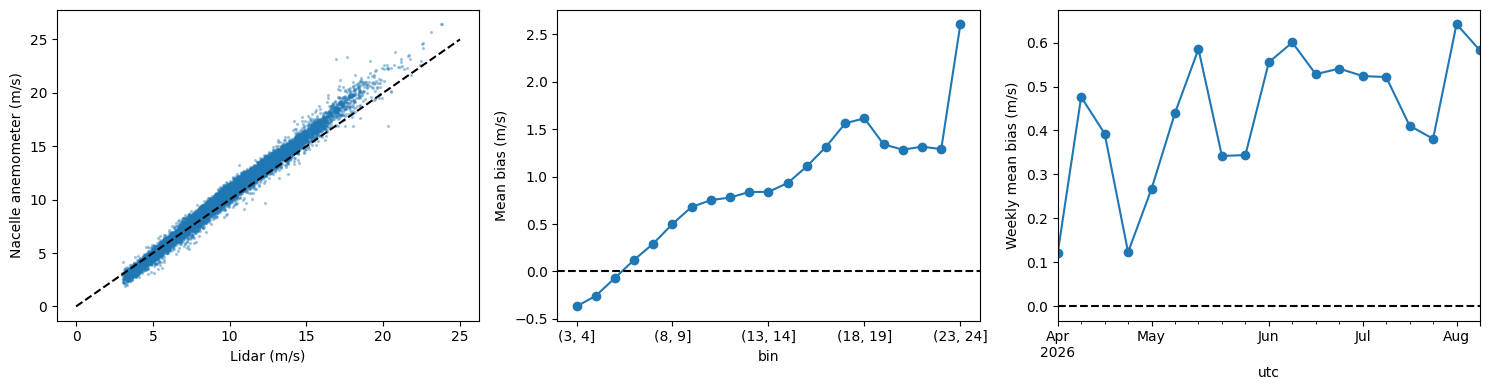

In [36]:
#subset turbine 184
wtg184 = scada[scada['turbine'] == 'WTG184']

#combine lidar and scada
wtg184_combined = pd.merge(lidar184, wtg184, on="utc", how="inner")
wtg184_combined = wtg184_combined.rename(columns={"KPI_wind_speed": "ws_anem", "wind_speed_l": "ws_lidar", "KPI_real_power_ac": "power"})

#filter out nas, when the turbine is off, and outliers (turbines performing outside of normal operating range)
wtg184_combined = wtg184_combined[
    (wtg184_combined["ws_lidar"].between(3, 25)) &          # normal operating range
    (wtg184_combined["power"] > 0)                         # turbine actually running
].dropna(subset=["ws_anem", "ws_lidar"])

#compute bias, rmse and plot
diff = wtg184_combined["ws_anem"] - wtg184_combined["ws_lidar"]
print("Bias:", diff.mean(), " RMSE:", np.sqrt((diff**2).mean()))
slope, intercept = np.polyfit(wtg184_combined["ws_lidar"], wtg184_combined["ws_anem"], 1)
print(f"anem = {slope:.3f} * lidar + {intercept:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Scatter vs 1:1 line
ax[0].scatter(wtg184_combined["ws_lidar"], wtg184_combined["ws_anem"], s=2, alpha=0.3)
ax[0].plot([0, 25], [0, 25], "k--")
ax[0].set(xlabel="Lidar (m/s)", ylabel="Nacelle anemometer (m/s)")

# Bias by wind speed bin
bins = np.arange(3, 26, 1)
wtg184_combined["bin"] = pd.cut(wtg184_combined["ws_lidar"], bins)
wtg184_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(ylabel="Mean bias (m/s)")

# Bias over time: this is where faults show up
diff.groupby(wtg184_combined["utc"].dt.to_period("W")).mean().plot(ax=ax[2], marker="o")
ax[2].axhline(0, color="k", ls="--"); ax[2].set(ylabel="Weekly mean bias (m/s)")
plt.tight_layout()

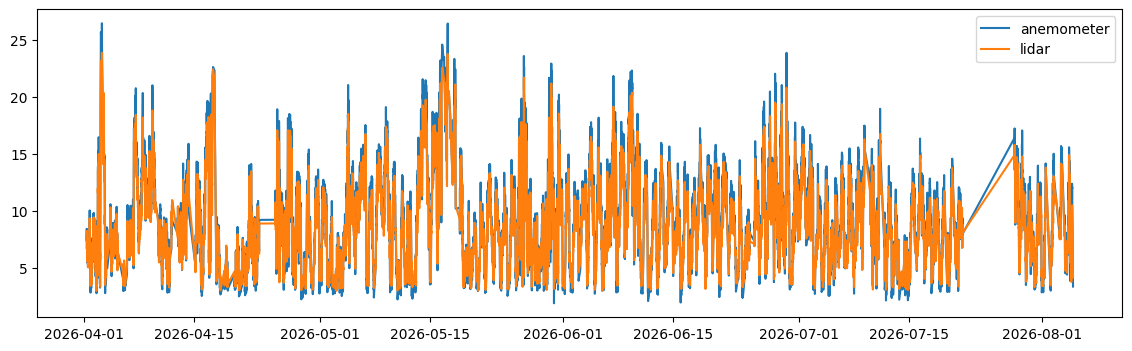

In [37]:
#time series
wk = wtg184_combined[(wtg184_combined["utc"] >= "2026-04-01") & (wtg184_combined["utc"] < "2026-09-30")]   
plt.figure(figsize=(14, 4))
plt.plot(wk["utc"], wk["ws_anem"], label="anemometer")
plt.plot(wk["utc"], wk["ws_lidar"], label="lidar")
plt.legend()

## turbine 170

Bias: 0.31389779222789116  RMSE: 0.5699119835029696
anem = 1.028 * lidar + 0.059


/var/folders/gq/h1h8jf9s2ljgh3cq6yfxgcbm0000gn/T/ipykernel_34622/1686944021.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wtg170_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")


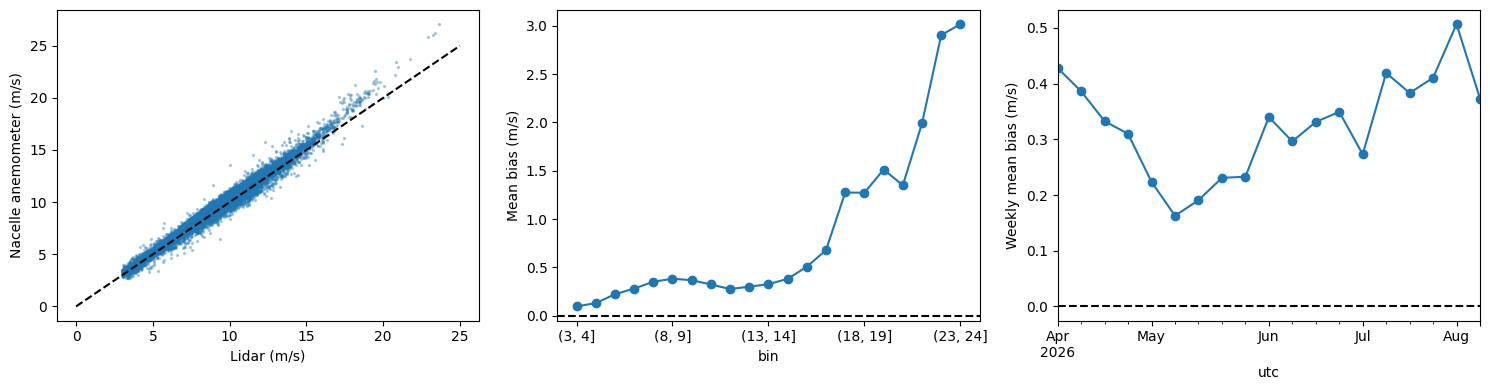

In [38]:
#subset turbine 170
wtg170 = scada[scada['turbine'] == 'WTG170']

#combine lidar and scada
wtg170_combined = pd.merge(lidar170, wtg170, on="utc", how="inner")
wtg170_combined = wtg170_combined.rename(columns={"KPI_wind_speed": "ws_anem", "wind_speed_l": "ws_lidar", "KPI_real_power_ac": "power"})

#filter out nas, when the turbine is off, and outliers (turbines performing outside of normal operating range)
wtg170_combined = wtg170_combined[
    (wtg170_combined["ws_lidar"].between(3, 25)) &          # normal operating range
    (wtg170_combined["power"] > 0)                         # turbine actually running
].dropna(subset=["ws_anem", "ws_lidar"])

#compute bias, rmse and plot
diff = wtg170_combined["ws_anem"] - wtg170_combined["ws_lidar"]
print("Bias:", diff.mean(), " RMSE:", np.sqrt((diff**2).mean()))
slope, intercept = np.polyfit(wtg170_combined["ws_lidar"], wtg170_combined["ws_anem"], 1)
print(f"anem = {slope:.3f} * lidar + {intercept:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Scatter vs 1:1 line
ax[0].scatter(wtg170_combined["ws_lidar"], wtg170_combined["ws_anem"], s=2, alpha=0.3)
ax[0].plot([0, 25], [0, 25], "k--")
ax[0].set(xlabel="Lidar (m/s)", ylabel="Nacelle anemometer (m/s)")

# Bias by wind speed bin
bins = np.arange(3, 26, 1)
wtg170_combined["bin"] = pd.cut(wtg170_combined["ws_lidar"], bins)
wtg170_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(ylabel="Mean bias (m/s)")

# Bias over time: this is where faults show up
diff.groupby(wtg170_combined["utc"].dt.to_period("W")).mean().plot(ax=ax[2], marker="o")
ax[2].axhline(0, color="k", ls="--"); ax[2].set(ylabel="Weekly mean bias (m/s)")
plt.tight_layout()

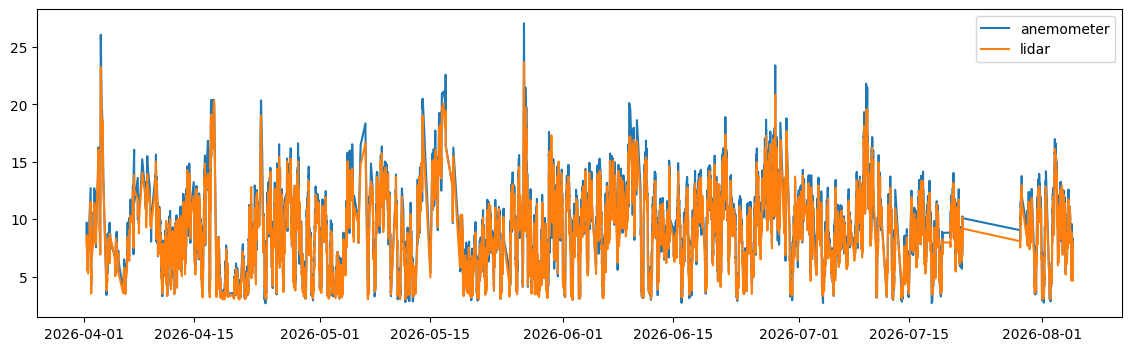

In [39]:
#time series 
wk = wtg170_combined[(wtg170_combined["utc"] >= "2026-04-01") & (wtg170_combined["utc"] < "2026-09-30")]   
plt.figure(figsize=(14, 4))
plt.plot(wk["utc"], wk["ws_anem"], label="anemometer")
plt.plot(wk["utc"], wk["ws_lidar"], label="lidar")
plt.legend()

## turbine 171

In [ ]:
#subset turbine 170
wtg171 = scada[scada['turbine'] == 'WTG171']

#combine lidar and scada
wtg170_combined = pd.merge(lidar170, wtg170, on="utc", how="inner")
wtg170_combined = wtg170_combined.rename(columns={"KPI_wind_speed": "ws_anem", "wind_speed_l": "ws_lidar", "KPI_real_power_ac": "power"})

#filter out nas, when the turbine is off, and outliers (turbines performing outside of normal operating range)
wtg170_combined = wtg170_combined[
    (wtg170_combined["ws_lidar"].between(3, 25)) &          # normal operating range
    (wtg170_combined["power"] > 0)                         # turbine actually running
].dropna(subset=["ws_anem", "ws_lidar"])

#compute bias, rmse and plot
diff = wtg170_combined["ws_anem"] - wtg170_combined["ws_lidar"]
print("Bias:", diff.mean(), " RMSE:", np.sqrt((diff**2).mean()))
slope, intercept = np.polyfit(wtg170_combined["ws_lidar"], wtg170_combined["ws_anem"], 1)
print(f"anem = {slope:.3f} * lidar + {intercept:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Scatter vs 1:1 line
ax[0].scatter(wtg170_combined["ws_lidar"], wtg170_combined["ws_anem"], s=2, alpha=0.3)
ax[0].plot([0, 25], [0, 25], "k--")
ax[0].set(xlabel="Lidar (m/s)", ylabel="Nacelle anemometer (m/s)")

# Bias by wind speed bin
bins = np.arange(3, 26, 1)
wtg170_combined["bin"] = pd.cut(wtg170_combined["ws_lidar"], bins)
wtg170_combined.groupby("bin", observed=True).apply(lambda g: (g.ws_anem - g.ws_lidar).mean()).plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(ylabel="Mean bias (m/s)")

# Bias over time: this is where faults show up
diff.groupby(wtg170_combined["utc"].dt.to_period("W")).mean().plot(ax=ax[2], marker="o")
ax[2].axhline(0, color="k", ls="--"); ax[2].set(ylabel="Weekly mean bias (m/s)")
plt.tight_layout()

## turbine 173